<a href="https://colab.research.google.com/github/Jorgellamocca/S2S-PER/blob/main/APS-GEFS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# ============================================================
# INSTALACIÓN SILENCIOSA DE DEPENDENCIAS
# ============================================================

import subprocess
import sys

subprocess.run(
    [
        sys.executable, "-m", "pip", "install",
        "-q",
        "requests==2.32.4",
        "fsspec==2025.12.0",
        "gcsfs==2025.12.0",
        "xarray>=2025.1.2",
        "zarr>=3.0.4",
        "aiohttp",
        "dask[array]",
        "matplotlib",
        "pandas",
        "numpy"
    ],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL,
    check=True
)

print("✓ Instalación completada correctamente.")

✓ Instalación completada correctamente.


NOAA GEFS | HOVMÖLLER DIARIO | APS

DIMENSIONES:
Frozen({'init_time': 2217, 'ensemble_member': 31, 'lead_time': 181, 'latitude': 721, 'longitude': 1440})

VERIFICACIÓN DE INICIALIZACIONES
2026-10-26 00:00:00 | Horizonte: 16.0 días
2026-10-25 00:00:00 | Horizonte: 35.0 días

INICIALIZACIÓN SELECCIONADA:
2026-10-25 00:00:00
Horizonte: 35 días

SELECCIÓN DEL CORTE MERIDIONAL
Longitud seleccionada: -90.0
Latitudes: 261
Miembros del ensamble: 31

DIAGNÓSTICO DEL PRONÓSTICO
Inicialización: 2026-10-25 00:00:00
Días disponibles: 35
Primer día: 1
Último día: 35
Días faltantes: []

MATRIZ FINAL:
Latitudes: 261
Días: 35
Forma: (261, 35)
Presión mínima: 993.02 hPa
Presión máxima: 1029.3 hPa


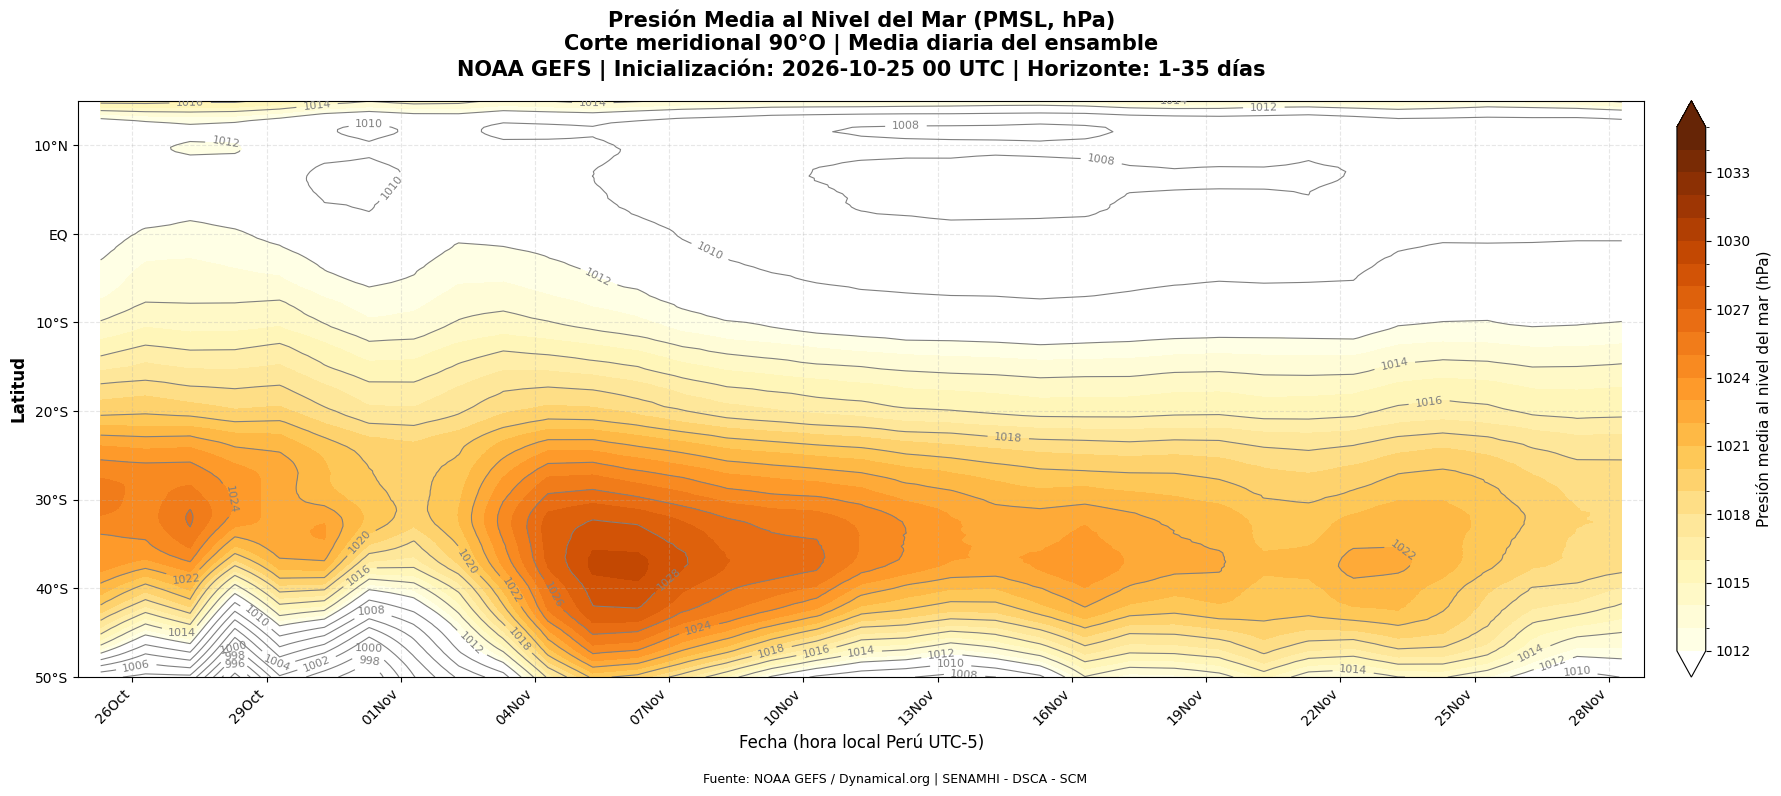

In [6]:
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import BoundaryNorm

# ============================================================
# NOAA GEFS | HOVMÖLLER DIARIO DE PRESIÓN AL NIVEL DEL MAR
# ANTICICLÓN DEL PACÍFICO SUR (APS)
#
# - Inicialización automática con 35 días disponibles
# - Media de los miembros del ensamble
# - Promedio diario de presión
# - Corte meridional 90°O
# - Hora local Perú (UTC-5)
# - Isobaras cada 2 hPa
# - SIN GUARDAR ARCHIVOS
# ============================================================

URL = (
    "https://data.dynamical.org/noaa/gefs/"
    "forecast-35-day/latest.zarr"
)

VARIABLE = "pressure_reduced_to_mean_sea_level"

LON_CORTE = -90.0
LAT_MIN = -50.0
LAT_MAX = 15.0

N_DIAS = 35

# ------------------------------------------------------------
# 1. ABRIR DATASET
# ------------------------------------------------------------

print("=" * 75)
print("NOAA GEFS | HOVMÖLLER DIARIO | APS")
print("=" * 75)

ds = xr.open_zarr(
    URL,
    consolidated=None,
    chunks="auto"
)

if VARIABLE not in ds.data_vars:
    raise KeyError(
        f"No se encontró {VARIABLE}.\n"
        f"Variables disponibles: {list(ds.data_vars)}"
    )

print("\nDIMENSIONES:")
print(ds.sizes)

# ------------------------------------------------------------
# 2. IDENTIFICAR LONGITUD
# ------------------------------------------------------------

lon = LON_CORTE

if float(ds.longitude.max()) > 180:
    lon = LON_CORTE % 360

# ------------------------------------------------------------
# 3. BUSCAR INICIALIZACIÓN CON 35 DÍAS
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("VERIFICACIÓN DE INICIALIZACIONES")
print("=" * 75)

init_seleccionada = None

for fecha in ds.init_time.values[::-1]:

    prueba = ds[VARIABLE].sel(
        init_time=fecha,
        latitude=-30.0,
        longitude=lon,
        method="nearest"
    )

    if "ensemble_member" in prueba.dims:
        prueba = prueba.isel(
            ensemble_member=0
        )

    prueba = prueba.compute()

    horas = (
        pd.to_timedelta(prueba.lead_time.values)
        / pd.Timedelta(hours=1)
    ).to_numpy()

    validos = np.isfinite(prueba.values)

    horas_validas = horas[validos]

    if len(horas_validas) == 0:

        print(
            pd.to_datetime(fecha),
            "| Sin datos"
        )

        continue

    horizonte = horas_validas.max() / 24

    print(
        pd.to_datetime(fecha),
        f"| Horizonte: {horizonte:.1f} días"
    )

    # Comprobar los 35 días de pronóstico
    dias_validos = np.ceil(
        horas_validas[horas_validas > 0] / 24
    ).astype(int)

    dias_presentes = set(dias_validos)

    completo = all(
        d in dias_presentes
        for d in range(1, N_DIAS + 1)
    )

    if completo:

        init_seleccionada = fecha

        print("\nINICIALIZACIÓN SELECCIONADA:")
        print(pd.to_datetime(fecha))
        print("Horizonte: 35 días")

        break

if init_seleccionada is None:

    raise RuntimeError(
        "No se encontró una inicialización "
        "con 35 días disponibles."
    )

init = pd.Timestamp(init_seleccionada)

# ------------------------------------------------------------
# 4. SELECCIONAR CORTE MERIDIONAL
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("SELECCIÓN DEL CORTE MERIDIONAL")
print("=" * 75)

da = ds[VARIABLE].sel(
    init_time=init,
    longitude=lon,
    method="nearest"
)

da = da.where(
    (da.latitude >= LAT_MIN) &
    (da.latitude <= LAT_MAX),
    drop=True
)

print(
    "Longitud seleccionada:",
    float(da.longitude.values)
)

print(
    "Latitudes:",
    da.sizes["latitude"]
)

# ------------------------------------------------------------
# 5. PROMEDIO DEL ENSAMBLE
# ------------------------------------------------------------

if "ensemble_member" in da.dims:

    print(
        "Miembros del ensamble:",
        da.sizes["ensemble_member"]
    )

    da = da.mean(
        dim="ensemble_member",
        skipna=True
    )

# ------------------------------------------------------------
# 6. CONVERTIR PRESIÓN A hPa
# ------------------------------------------------------------

unidades = da.attrs.get(
    "units", ""
).strip().lower()

if unidades in ["pa", "pascal", "pascals"]:

    da = da / 100.0

elif unidades in ["hpa", "mbar", "millibar"]:

    pass

else:

    raise ValueError(
        f"Unidad de presión desconocida: {unidades}"
    )

# ------------------------------------------------------------
# 7. CONSTRUIR FECHAS VÁLIDAS
# ------------------------------------------------------------

fechas_utc = (
    init +
    pd.to_timedelta(da.lead_time.values)
)

da = da.assign_coords(
    forecast_time=(
        "lead_time",
        fechas_utc
    )
)

da = da.swap_dims({
    "lead_time": "forecast_time"
})

da = da.sortby("forecast_time")

# ------------------------------------------------------------
# 8. SELECCIONAR 35 DÍAS
# ------------------------------------------------------------

inicio = pd.Timestamp(init)

fin = inicio + pd.Timedelta(
    days=N_DIAS
)

da = da.sel(
    forecast_time=slice(
        inicio,
        fin
    )
)

# ------------------------------------------------------------
# 9. AGRUPACIÓN DIARIA
# ------------------------------------------------------------

# Día 1:  +0 a +24 h
# Día 2: +24 a +48 h
# ...
# Día 35: +816 a +840 h
#
# Se excluye +0 h y se utilizan intervalos
# (24*(día-1), 24*día].

horas = (
    (
        pd.DatetimeIndex(
            da.forecast_time.values
        ) - inicio
    ) / pd.Timedelta(hours=1)
).to_numpy()

dias_pronostico = np.ceil(
    horas / 24.0
).astype(int)

mask = (
    (dias_pronostico >= 1) &
    (dias_pronostico <= N_DIAS)
)

da = da.isel(
    forecast_time=np.flatnonzero(mask)
)

dias_pronostico = dias_pronostico[mask]

da = da.assign_coords(
    dia_pronostico=(
        "forecast_time",
        dias_pronostico
    )
)

da_diaria = da.groupby(
    "dia_pronostico"
).mean(
    dim="forecast_time",
    skipna=True
)

# Descargar solamente los datos seleccionados
da_diaria = da_diaria.compute()

# ------------------------------------------------------------
# 10. ORGANIZAR DATOS
# ------------------------------------------------------------

da_diaria = da_diaria.sortby(
    "latitude"
)

da_diaria = da_diaria.dropna(
    dim="dia_pronostico",
    how="all"
)

dias = da_diaria.dia_pronostico.values

if len(dias) == 0:
    raise RuntimeError(
        "No existen datos diarios válidos."
    )

# ------------------------------------------------------------
# 11. DIAGNÓSTICO
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("DIAGNÓSTICO DEL PRONÓSTICO")
print("=" * 75)

print("Inicialización:", inicio)
print("Días disponibles:", len(dias))
print("Primer día:", int(dias[0]))
print("Último día:", int(dias[-1]))

faltantes = sorted(
    set(range(1, N_DIAS + 1))
    - set(dias.astype(int))
)

print("Días faltantes:", faltantes)

# ------------------------------------------------------------
# 12. FECHAS EN HORA LOCAL PERÚ
# ------------------------------------------------------------

# Centro de cada intervalo de 24 horas

fechas_grafico = pd.DatetimeIndex([
    inicio + pd.Timedelta(
        hours=24 * (int(d) - 0.5)
    )
    for d in dias
])

fechas_peru = (
    fechas_grafico
    .tz_localize("UTC")
    .tz_convert("America/Lima")
    .tz_localize(None)
)

# Límites temporales completos

inicio_peru = (
    inicio
    .tz_localize("UTC")
    .tz_convert("America/Lima")
    .tz_localize(None)
)

fin_peru = inicio_peru + pd.Timedelta(
    days=N_DIAS
)

# ------------------------------------------------------------
# 13. MATRIZ PARA GRAFICAR
# ------------------------------------------------------------

latitudes = da_diaria.latitude.values

presion = da_diaria.transpose(
    "latitude",
    "dia_pronostico"
).values

X, Y = np.meshgrid(
    mdates.date2num(fechas_peru),
    latitudes
)

print("\nMATRIZ FINAL:")
print("Latitudes:", len(latitudes))
print("Días:", len(dias))
print("Forma:", presion.shape)

print(
    "Presión mínima:",
    round(float(np.nanmin(presion)), 2),
    "hPa"
)

print(
    "Presión máxima:",
    round(float(np.nanmax(presion)), 2),
    "hPa"
)

# ------------------------------------------------------------
# 14. CONFIGURACIÓN DE COLORES
# ------------------------------------------------------------

niveles_color = np.arange(
    1012, 1036, 1
)

niveles_contorno = np.arange(
    990, 1042, 2
)

cmap = plt.get_cmap(
    "YlOrBr"
).copy()

cmap.set_under("white")

norm = BoundaryNorm(
    niveles_color,
    cmap.N
)

# ------------------------------------------------------------
# 15. GENERAR HOVMÖLLER
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(18, 8)
)

cf = ax.contourf(
    X,
    Y,
    presion,
    levels=niveles_color,
    cmap=cmap,
    norm=norm,
    extend="both"
)

cs = ax.contour(
    X,
    Y,
    presion,
    levels=niveles_contorno,
    colors="gray",
    linewidths=0.8
)

ax.clabel(
    cs,
    inline=True,
    fontsize=8,
    fmt="%d"
)

# ------------------------------------------------------------
# 16. FORMATO DE LATITUDES
# ------------------------------------------------------------

lat_ticks = [
    -50, -40, -30,
    -20, -10, 0, 10
]

lat_labels = [
    "50°S",
    "40°S",
    "30°S",
    "20°S",
    "10°S",
    "EQ",
    "10°N"
]

ax.set_yticks(lat_ticks)
ax.set_yticklabels(lat_labels)

ax.set_ylim(
    LAT_MIN,
    LAT_MAX
)

# ------------------------------------------------------------
# 17. FORMATO DE FECHAS
# ------------------------------------------------------------

ax.xaxis.set_major_locator(
    mdates.DayLocator(interval=3)
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%d%b")
)

ax.set_xlim(
    inicio_peru,
    fin_peru
)

plt.setp(
    ax.get_xticklabels(),
    rotation=45,
    ha="right"
)

ax.grid(
    True,
    linestyle="--",
    alpha=0.3
)

# ------------------------------------------------------------
# 18. TÍTULO
# ------------------------------------------------------------

ax.set_title(
    "Presión Media al Nivel del Mar (PMSL, hPa)\n"
    "Corte meridional 90°O | Media diaria del ensamble\n"
    f"NOAA GEFS | Inicialización: "
    f"{inicio:%Y-%m-%d %H UTC} | "
    f"Horizonte: 1-{N_DIAS} días",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel(
    "Fecha (hora local Perú UTC-5)",
    fontsize=12
)

ax.set_ylabel(
    "Latitud",
    fontsize=12,
    fontweight="bold"
)

# ------------------------------------------------------------
# 19. BARRA DE COLORES
# ------------------------------------------------------------

cbar = fig.colorbar(
    cf,
    ax=ax,
    pad=0.02,
    fraction=0.025
)

cbar.set_label(
    "Presión media al nivel del mar (hPa)",
    fontsize=11
)

# ------------------------------------------------------------
# 20. CRÉDITOS
# ------------------------------------------------------------

fig.text(
    0.5,
    0.015,
    "Fuente: NOAA GEFS / Dynamical.org | "
    "SENAMHI - DSCA - SCM",
    ha="center",
    fontsize=9
)

plt.tight_layout(
    rect=[0, 0.035, 1, 1]
)

plt.show()

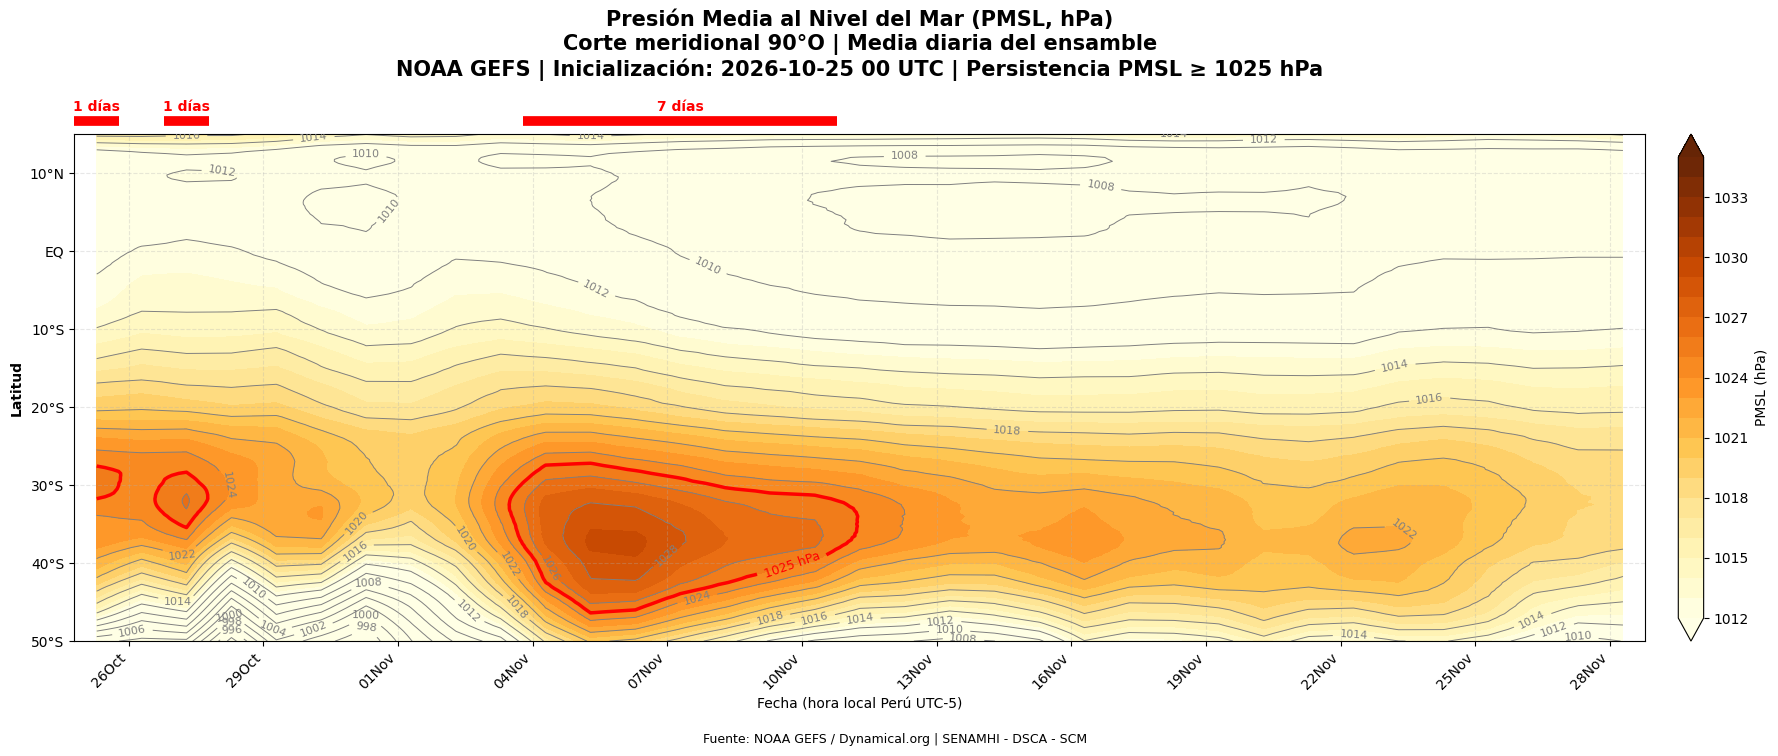


APS | PERSISTENCIA DE PMSL >= 1025 hPa
24/10/2026 - 25/10/2026 | 1 días
26/10/2026 - 27/10/2026 | 1 días
03/11/2026 - 10/11/2026 | 7 días


In [7]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.transforms as transforms
import numpy as np
import pandas as pd

# ============================================================
# GEFS | HOVMÖLLER APS
# RESALTAR PMSL >= 1025 hPa
# DURACIÓN Y FECHAS DE PERSISTENCIA
# ============================================================

UMBRAL = 1025.0

LAT_APS_MIN = -40.0
LAT_APS_MAX = -25.0

# ------------------------------------------------------------
# 1. IDENTIFICAR PRESIÓN >= 1025 hPa
# ------------------------------------------------------------

mask_lat = (
    (latitudes >= LAT_APS_MIN) &
    (latitudes <= LAT_APS_MAX)
)

if not np.any(mask_lat):
    raise ValueError(
        "No hay latitudes dentro de la franja APS."
    )

# Máxima presión diaria en la franja seleccionada
pmsl_max = np.nanmax(
    presion[mask_lat, :],
    axis=0
)

supera_umbral = pmsl_max >= UMBRAL

# ------------------------------------------------------------
# 2. IDENTIFICAR PERIODOS CONSECUTIVOS
# ------------------------------------------------------------

periodos = []
inicio_evento = None

for i, activo in enumerate(supera_umbral):

    if activo and inicio_evento is None:
        inicio_evento = i

    # Cerrar evento cuando termina o al llegar
    # al último día disponible
    if inicio_evento is not None:

        termina = (
            not activo or
            i == len(supera_umbral) - 1
        )

        if termina:

            fin_evento = (
                i if activo else i - 1
            )

            # Verificar continuidad real de los días
            segmento_inicio = inicio_evento

            for j in range(
                inicio_evento + 1,
                fin_evento + 2
            ):

                corte = (
                    j > fin_evento or
                    int(dias[j]) != int(dias[j-1]) + 1
                )

                if corte:

                    periodos.append(
                        (segmento_inicio, j - 1)
                    )

                    segmento_inicio = j

            inicio_evento = None

# ------------------------------------------------------------
# 3. GENERAR FIGURA
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(18, 8)
)

niveles_color = np.arange(
    1012, 1036, 1
)

niveles_contorno = np.arange(
    990, 1042, 2
)

cf = ax.contourf(
    X,
    Y,
    presion,
    levels=niveles_color,
    cmap="YlOrBr",
    extend="both"
)

cs = ax.contour(
    X,
    Y,
    presion,
    levels=niveles_contorno,
    colors="gray",
    linewidths=0.7
)

ax.clabel(
    cs,
    inline=True,
    fontsize=8,
    fmt="%d"
)

# ------------------------------------------------------------
# 4. RESALTAR ISOBARA DE 1025 hPa
# ------------------------------------------------------------

contorno_1025 = ax.contour(
    X,
    Y,
    presion,
    levels=[UMBRAL],
    colors="red",
    linewidths=2.5
)

ax.clabel(
    contorno_1025,
    fmt={UMBRAL: "1025 hPa"},
    fontsize=9,
    colors="red"
)

# ------------------------------------------------------------
# 5. BARRAS DE PERSISTENCIA EN PARTE SUPERIOR
# ------------------------------------------------------------

# X en coordenadas de fechas;
# Y en coordenadas relativas del eje.
trans = transforms.blended_transform_factory(
    ax.transData,
    ax.transAxes
)

for i0, i1 in periodos:

    fecha_inicio = (
        inicio_peru +
        pd.Timedelta(days=int(dias[i0])-1)
    )

    fecha_fin = (
        inicio_peru +
        pd.Timedelta(days=int(dias[i1]))
    )

    duracion = int(dias[i1] - dias[i0] + 1)

    # Franja superior
    ax.plot(
        [fecha_inicio, fecha_fin],
        [1.025, 1.025],
        color="red",
        linewidth=7,
        solid_capstyle="butt",
        transform=trans,
        clip_on=False
    )

    # Duración sobre la franja
    fecha_centro = (
        fecha_inicio +
        (fecha_fin - fecha_inicio) / 2
    )

    ax.text(
        fecha_centro,
        1.045,
        f"{duracion} días",
        color="red",
        fontsize=10,
        fontweight="bold",
        ha="center",
        transform=trans,
        clip_on=False
    )

# ------------------------------------------------------------
# 6. FORMATO DE LATITUDES
# ------------------------------------------------------------

lat_ticks = [
    -50, -40, -30, -20, -10, 0, 10
]

lat_labels = [
    "50°S", "40°S", "30°S",
    "20°S", "10°S", "EQ", "10°N"
]

ax.set_yticks(lat_ticks)
ax.set_yticklabels(lat_labels)

ax.set_ylim(-50, 15)

# ------------------------------------------------------------
# 7. FORMATO DE FECHAS
# ------------------------------------------------------------

ax.xaxis.set_major_locator(
    mdates.DayLocator(interval=3)
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%d%b")
)

ax.set_xlim(
    inicio_peru,
    fin_peru
)

plt.setp(
    ax.get_xticklabels(),
    rotation=45,
    ha="right"
)

ax.grid(
    linestyle="--",
    alpha=0.3
)

# ------------------------------------------------------------
# 8. TÍTULO Y COLORBAR
# ------------------------------------------------------------

ax.set_title(
    "Presión Media al Nivel del Mar (PMSL, hPa)\n"
    "Corte meridional 90°O | Media diaria del ensamble\n"
    f"NOAA GEFS | Inicialización: "
    f"{inicio:%Y-%m-%d %H UTC} | "
    "Persistencia PMSL ≥ 1025 hPa",
    fontsize=15,
    fontweight="bold",
    pad=42
)

ax.set_xlabel(
    "Fecha (hora local Perú UTC-5)"
)

ax.set_ylabel(
    "Latitud",
    fontweight="bold"
)

cbar = fig.colorbar(
    cf,
    ax=ax,
    pad=0.02,
    fraction=0.025
)

cbar.set_label(
    "PMSL (hPa)"
)

fig.text(
    0.5,
    0.015,
    "Fuente: NOAA GEFS / Dynamical.org | "
    "SENAMHI - DSCA - SCM",
    ha="center",
    fontsize=9
)

plt.tight_layout(
    rect=[0, 0.035, 1, 0.95]
)

plt.show()

# ------------------------------------------------------------
# 9. RESUMEN DE PERIODOS
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("APS | PERSISTENCIA DE PMSL >= 1025 hPa")
print("=" * 75)

for i0, i1 in periodos:

    fecha_inicio = (
        inicio_peru +
        pd.Timedelta(days=int(dias[i0])-1)
    )

    fecha_fin = (
        inicio_peru +
        pd.Timedelta(days=int(dias[i1]))
    )

    duracion = int(dias[i1] - dias[i0] + 1)

    print(
        f"{fecha_inicio:%d/%m/%Y} - "
        f"{fecha_fin:%d/%m/%Y} | "
        f"{duracion} días"
    )

if not periodos:
    print("No se identificaron periodos con PMSL >= 1025 hPa.")